## Geometric features extraction and classifier testing

In [1]:
import re
import urllib.request
from pathlib import Path

import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, ConfusionMatrixDisplay)

FOLDER = Path("../data/dataset_squat")
CONDITIONS = ["pre", "per", "post"]
SEED = 42 
Path("figures").mkdir(exist_ok=True)

In [2]:
# All images
files = pd.DataFrame([
    {"path": str(path), "condition": condition}
    for condition in CONDITIONS
    for path in sorted((FOLDER / f"squat_{condition}").glob("*.jpg"))
])

# Random stratified split 60/20/20
trainval, test = train_test_split(
    files, test_size=0.20, stratify=files["condition"], random_state=SEED)
train, val = train_test_split(
    trainval, test_size=0.25, stratify=trainval["condition"], random_state=SEED)

# No overlap between train, validation and test sets
assert not (set(train["path"]) & set(val["path"]))
assert not (set(train["path"]) & set(test["path"]))
assert not (set(val["path"]) & set(test["path"]))

splits = pd.concat([train.assign(set="train"), val.assign(set="val"), test.assign(set="test")])
splits.to_csv("splits.csv", index=False)

print(pd.crosstab(splits["set"], splits["condition"]).loc[["train", "val", "test"], CONDITIONS])

condition  pre  per  post
set                      
train      300  300   300
val        100  100   100
test       100  100   100


In [3]:
# Viola-Jones face detection algorithm
_CASCADE = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)
if _CASCADE.empty():
    raise RuntimeError("Cascade not loaded: verify OpenCV installation")


def face_detect(image, scale_factor=1.1, min_neighbors=5,
                    min_size=(60, 60), roi_ratio=1.0):
    """
    Detect face (Viola-Jones) and return the cropped BGR image.
    image     : path (str / Path) or BGR table
    roi_ratio : central fraction of the bounding box kept (0.6 = centre du visage)
    Returns (face_bgr, bbox) or (None, None) if no face is found.
    """
    img = cv2.imread(str(image)) if isinstance(image, (str, Path)) else image
    if img is None:
        raise FileNotFoundError(f"Unable to read image: {image}")

    grey = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = _CASCADE.detectMultiScale(
        grey, scaleFactor=scale_factor,
        minNeighbors=min_neighbors, minSize=min_size,
    )
    if len(faces) == 0:
        return None, None

    x, y, w, h = max(faces, key=lambda b: b[2] * b[3])                  # we keep the largest detected face
    dx, dy = int(w * (1 - roi_ratio) / 2), int(h * (1 - roi_ratio) / 2) # central crop
    face = img[y + dy : y + h - dy, x + dx : x + w - dx]
    return face, (int(x), int(y), int(w), int(h))

In [4]:
# Remove pixels outside the detected face without cropping facial information
def remove_face_background(face, iterations=1):
    """Return a background-replaced face and its GrabCut foreground mask."""
    height, width = face.shape[:2]
    mask = np.full((height, width), cv2.GC_PR_BGD, dtype=np.uint8)
    border = max(2, int(min(height, width) * 0.04))
    mask[border:-border, border:-border] = cv2.GC_PR_FGD
    cv2.ellipse(mask, (width // 2, height // 2),
                (int(width * 0.42), int(height * 0.48)), 0, 0, 360, cv2.GC_FGD, -1)
    background_model = np.zeros((1, 65), np.float64)
    foreground_model = np.zeros((1, 65), np.float64)
    cv2.grabCut(face, mask, None, background_model, foreground_model,
                iterations, cv2.GC_INIT_WITH_MASK)
    foreground = np.isin(mask, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    foreground = cv2.morphologyEx(foreground, cv2.MORPH_CLOSE, kernel)
    foreground = cv2.morphologyEx(foreground, cv2.MORPH_OPEN, kernel)
    border_pixels = np.concatenate((face[:border].reshape(-1, 3), face[-border:].reshape(-1, 3)))
    background_color = np.median(border_pixels, axis=0).astype(np.uint8)
    cleaned = np.broadcast_to(background_color, face.shape).copy()
    cleaned[foreground > 0] = face[foreground > 0]
    return cleaned, foreground


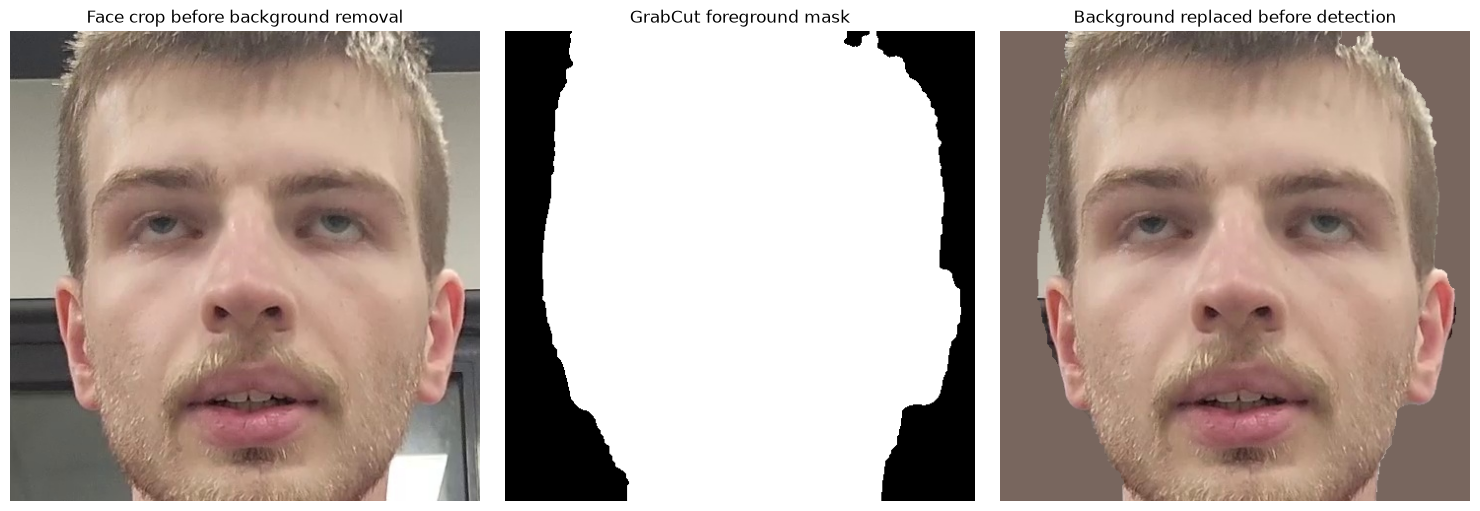

In [5]:
# Background-removal diagnostic (before eye/mouth detection)
# We use the same test image as for the ending detection diagnostics cell
background_sample = test.sample(n=1, random_state=SEED).iloc[0]
background_face, _ = face_detect(background_sample["path"])
if background_face is None:
    raise RuntimeError(f"No face detected in background diagnostic: {background_sample['path']}")
background_removed, foreground_mask = remove_face_background(background_face)
background_overlay = background_face.copy()
background_overlay[foreground_mask == 0] = (0, 0, 255)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(cv2.cvtColor(background_face, cv2.COLOR_BGR2RGB))
axes[0].set_title("Face crop before background removal")
axes[1].imshow(foreground_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("GrabCut foreground mask")
axes[2].imshow(cv2.cvtColor(background_removed, cv2.COLOR_BGR2RGB))
axes[2].set_title("Background replaced before detection")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
# Landmarks detection and features extraction
def _empty_morphology_features():
    """Return the complete finite schema used when a face or contour is unavailable."""
    return {
        "eye_left_opening_ratio": 0.0, "eye_right_opening_ratio": 0.0,
        "eye_opening_asymmetry": 0.0, "eye_left_area": 0.0,
        "eye_right_area": 0.0, "eye_left_edge_density": 0.0,
        "eye_right_edge_density": 0.0, "eye_edge_density_asymmetry": 0.0,
        "eye_left_width": 0.0, "eye_left_height": 0.0,
        "eye_right_width": 0.0, "eye_right_height": 0.0,
        "eye_left_area": 0.0, "eye_right_area": 0.0,
        "mouth_opening_ratio": 0.0, "mouth_width": 0.0, "mouth_height": 0.0,
        "mouth_outer_area": 0.0, "mouth_inner_area": 0.0,
        "mouth_corner_angle_deg": 0.0, "mouth_edge_density": 0.0,
        "mouth_structure_detected": 0.0, "face_edge_density": 0.0,
        "left_right_edge_asymmetry": 0.0,
    }


def _roi(gray, x0, y0, x1, y1):
    height, width = gray.shape[:2]
    return gray[int(height * y0):int(height * y1), int(width * x0):int(width * x1)]

_LANDMARK_GROUPS = {
    "left_eye": [33, 160, 158, 133, 153, 144],
    "right_eye": [362, 385, 387, 263, 373, 380],
    "mouth_outer": [61, 146, 91, 181, 84, 17, 314, 405, 321, 375,
                     291, 409, 270, 269, 267, 0, 37, 39, 40],
    "mouth_inner": [78, 95, 88, 178, 87, 14, 317, 402, 318, 324,
                    308, 415, 310, 311, 312, 13, 82, 81],
}

_LANDMARK_MODEL = Path("models/face_landmarker.task")
_LANDMARK_MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/face_landmarker/"
    "face_landmarker/float16/1/face_landmarker.task"
)
if not _LANDMARK_MODEL.exists():
    _LANDMARK_MODEL.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(_LANDMARK_MODEL_URL, _LANDMARK_MODEL)
_FACE_LANDMARKER = mp.tasks.vision.FaceLandmarker.create_from_options(
    mp.tasks.vision.FaceLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=str(_LANDMARK_MODEL)),
        running_mode=mp.tasks.vision.RunningMode.IMAGE,
        num_faces=1,
        min_face_detection_confidence=0.5,
        min_face_presence_confidence=0.5,
    )
)


def _landmark_points(face):
    rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
    result = _FACE_LANDMARKER.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not result.face_landmarks:
        return None
    height, width = face.shape[:2]
    landmarks = result.face_landmarks[0]
    points = np.array([(landmarks[i].x * width, landmarks[i].y * height)
                       for i in range(len(landmarks))], dtype=np.float32)
    return points if np.isfinite(points).all() else None


def _landmark_polygon(points, indices):
    return points[np.asarray(indices, dtype=int)]


def _landmark_distance(points, first, second):
    return float(np.linalg.norm(points[first] - points[second]))


def _landmark_area(points):
    if points is None or not np.isfinite(points).all():
        return 0.0
    area = float(abs(cv2.contourArea(points.astype(np.float32))))
    return area if np.isfinite(area) else 0.0


def _landmark_geometry(points):
    if points is None:
        return _empty_morphology_features()
    groups = {name: _landmark_polygon(points, indices)
              for name, indices in _LANDMARK_GROUPS.items()}
    interocular = max(_landmark_distance(points, 33, 263), 1.0)
    left_width = _landmark_distance(points, 33, 133) / interocular
    right_width = _landmark_distance(points, 362, 263) / interocular
    left_height = np.mean([_landmark_distance(points, 160, 144),
                           _landmark_distance(points, 158, 153)]) / interocular
    right_height = np.mean([_landmark_distance(points, 385, 380),
                            _landmark_distance(points, 387, 373)]) / interocular
    mouth_width = _landmark_distance(points, 61, 291) / interocular
    mouth_height = _landmark_distance(points, 13, 14) / interocular
    outer = groups["mouth_outer"]
    inner = groups["mouth_inner"]
    return {
        "eye_left_opening_ratio": float(left_height / max(left_width, 1e-6)),
        "eye_right_opening_ratio": float(right_height / max(right_width, 1e-6)),
        "eye_opening_asymmetry": float(abs(left_height - right_height)),
        "eye_left_width": float(left_width), "eye_left_height": float(left_height),
        "eye_right_width": float(right_width), "eye_right_height": float(right_height),
        "eye_left_area": _landmark_area(groups["left_eye"]) / interocular ** 2,
        "eye_right_area": _landmark_area(groups["right_eye"]) / interocular ** 2,
        "mouth_opening_ratio": float(mouth_height / max(mouth_width, 1e-6)),
        "mouth_width": float(mouth_width), "mouth_height": float(mouth_height),
        "mouth_outer_area": _landmark_area(outer) / interocular ** 2,
        "mouth_inner_area": _landmark_area(inner) / interocular ** 2,
        "mouth_corner_angle_deg": float(np.degrees(np.arctan2(
            points[13, 1] - (points[61, 1] + points[291, 1]) / 2,
            max(_landmark_distance(points, 61, 291), 1.0)))),
    }


def extract_contour_features(face):
    """Return landmark geometry and edge-density features."""
    height, width = face.shape[:2]
    gray = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY)
    points = _landmark_points(face)
    features = _landmark_geometry(points)
    left_eye_region = _roi(gray, 0.08, 0.22, 0.52, 0.62)
    right_eye_region = _roi(gray, 0.48, 0.22, 0.92, 0.62)
    mouth_region = _roi(gray, 0.16, 0.48, 0.84, 0.96)
    left_eye = {"opening_ratio": features["eye_left_opening_ratio"], "area": features["eye_left_area"],
                "width": features["eye_left_width"], "height": features["eye_left_height"]}
    right_eye = {"opening_ratio": features["eye_right_opening_ratio"], "area": features["eye_right_area"],
                 "width": features["eye_right_width"], "height": features["eye_right_height"]}
    mouth = {"outer_area": features["mouth_outer_area"], "inner_area": features["mouth_inner_area"],
             "opening_ratio": features["mouth_opening_ratio"], "width": features["mouth_width"], "height": features["mouth_height"],
             "corner_angle_deg": features["mouth_corner_angle_deg"]}
    left_edge_density = float(np.mean(cv2.Canny(left_eye_region, 30, 100) > 0))
    right_edge_density = float(np.mean(cv2.Canny(right_eye_region, 30, 100) > 0))
    mouth_edge_density = float(np.mean(cv2.Canny(mouth_region, 30, 100) > 0))
    face_edges = cv2.Canny(gray, 30, 100)
    half_width = width // 2
    left_edges = face_edges[:, :half_width].astype(float)
    right_edges = np.fliplr(face_edges[:, width - half_width:].astype(float))
    features.update({
        "eye_left_opening_ratio": left_eye["opening_ratio"],
        "eye_right_opening_ratio": right_eye["opening_ratio"],
        "eye_opening_asymmetry": abs(left_eye["opening_ratio"] - right_eye["opening_ratio"]),
        "eye_left_area": left_eye["area"],
        "eye_right_area": right_eye["area"],
        "eye_left_edge_density": left_edge_density,
        "eye_right_edge_density": right_edge_density,
        "eye_edge_density_asymmetry": abs(left_edge_density - right_edge_density),
        "eye_left_width": left_eye["width"],
        "eye_left_height": left_eye["height"],
        "eye_right_width": right_eye["width"],
        "eye_right_height": right_eye["height"],
        "mouth_outer_area": mouth["outer_area"],
        "mouth_inner_area": mouth["inner_area"],
        "mouth_opening_ratio": mouth["opening_ratio"],
        "mouth_width": mouth["width"],
        "mouth_height": mouth["height"],
        "mouth_corner_angle_deg": mouth["corner_angle_deg"],
        "mouth_edge_density": mouth_edge_density,
        "mouth_structure_detected": float(points is not None),
        "face_edge_density": float(np.mean(face_edges > 0)),
        "left_right_edge_asymmetry": float(np.mean(np.abs(left_edges - right_edges)) / 255.0),
    })
    return features


def build_contour_dataset(frame):
    rows = []
    for record in frame.itertuples(index=False):
        face, _ = face_detect(record.path)
        if face is not None:
            face, _ = remove_face_background(face)
        geometry = extract_contour_features(face) if face is not None else _empty_morphology_features()
        rows.append({"path": record.path, "condition": record.condition, "set": record.set,
                     "face_detected": float(face is not None), **geometry})
    result = pd.DataFrame(rows)
    feature_columns = [column for column in result.columns if column not in ("path", "condition", "set")]
    values = result[feature_columns].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        invalid = result[feature_columns].columns[~np.isfinite(values).all(axis=0)].tolist()
        raise ValueError(f"Non-finite geometric features generated: {invalid}")
    return result


data = build_contour_dataset(splits)
print(data)
data.to_csv("geometric_features.csv", index=False)


                                                   path condition    set  \
0     ..\data\dataset_squat\squat_per\squat_per_trai...       per  train   
1     ..\data\dataset_squat\squat_per\squat_per_trai...       per  train   
2     ..\data\dataset_squat\squat_post\squat_post_tr...      post  train   
3     ..\data\dataset_squat\squat_per\squat_per_trai...       per  train   
4     ..\data\dataset_squat\squat_post\squat_post_tr...      post  train   
...                                                 ...       ...    ...   
1495  ..\data\dataset_squat\squat_per\squat_per_trai...       per   test   
1496  ..\data\dataset_squat\squat_post\squat_post_tr...      post   test   
1497  ..\data\dataset_squat\squat_pre\squat_preth_fr...       pre   test   
1498  ..\data\dataset_squat\squat_per\squat_per_trai...       per   test   
1499  ..\data\dataset_squat\squat_pre\squat_prejoel_...       pre   test   

      face_detected  eye_left_opening_ratio  eye_right_opening_ratio  \
0              

In [13]:
META = ["path", "condition", "set"]
EXCLUDE = ()
FEATURES = [c for c in data.columns if c not in META and not c.startswith(EXCLUDE)]

d_train, d_val, d_test = (data[data["set"] == j] for j in ("train", "val", "test"))
X_train, y_train = d_train[FEATURES], d_train["condition"]
X_val,   y_val   = d_val[FEATURES],   d_val["condition"]
X_test,  y_test  = d_test[FEATURES],  d_test["condition"]
print(f"{len(FEATURES)} features used")

models = {
    "Baseline (stratified)": DummyClassifier(strategy="stratified", random_state=SEED),
    "KNN": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1)),
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
}

# Comparison on validation set
scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    scores[name] = {"accuracy": accuracy_score(y_val, pred),
                   "balanced_accuracy": balanced_accuracy_score(y_val, pred)}

scores_df = pd.DataFrame(scores).T.round(3)
print(scores_df)

best_model = max(scores, key=lambda n: scores[n]["balanced_accuracy"])
print("Best model on validation :", best_model)

# Random Forest (for explainable predictions) trained on train + val
final_model = models["Random Forest"]
final_model.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

23 features used
                       accuracy  balanced_accuracy
Baseline (stratified)     0.343              0.343
KNN                       0.947              0.947
Logistic Regression       0.910              0.910
Random Forest             0.947              0.947
Best model on validation : KNN


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

Model: Random Forest
Accuracy          : 0.947
Balanced accuracy : 0.947

              precision    recall  f1-score   support

         pre       0.97      0.95      0.96       100
         per       0.95      0.95      0.95       100
        post       0.92      0.94      0.93       100

    accuracy                           0.95       300
   macro avg       0.95      0.95      0.95       300
weighted avg       0.95      0.95      0.95       300



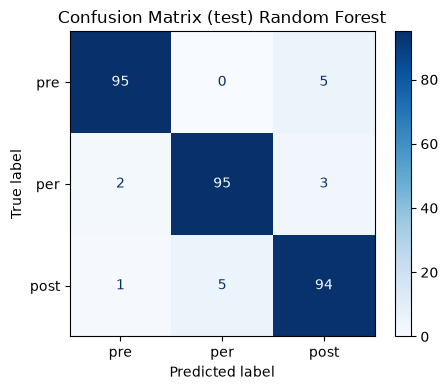

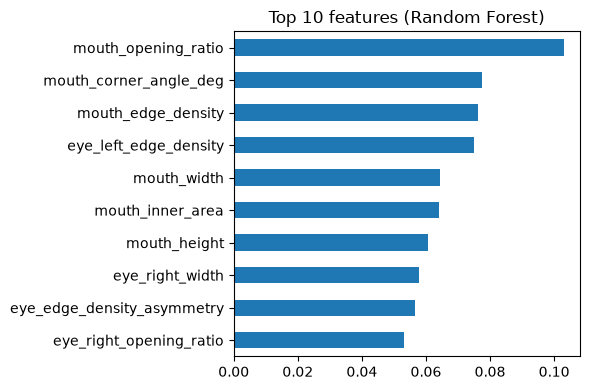

In [15]:
# Final evaluation on test
pred_test = final_model.predict(X_test)

print(f"Model: Random Forest")
print(f"Accuracy          : {accuracy_score(y_test, pred_test):.3f}")
print(f"Balanced accuracy : {balanced_accuracy_score(y_test, pred_test):.3f}\n")
print(classification_report(y_test, pred_test, labels=CONDITIONS, zero_division=0))

# Confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, labels=CONDITIONS, cmap="Blues", ax=ax)
ax.set_title(f"Confusion Matrix (test) Random Forest")
plt.tight_layout()
plt.savefig("figures/confusion_geometry_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

# Feature importance 
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values().tail(10)
imp.plot.barh(figsize=(6, 4), title="Top 10 features (Random Forest)")
plt.tight_layout()
plt.savefig("figures/importance_features_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

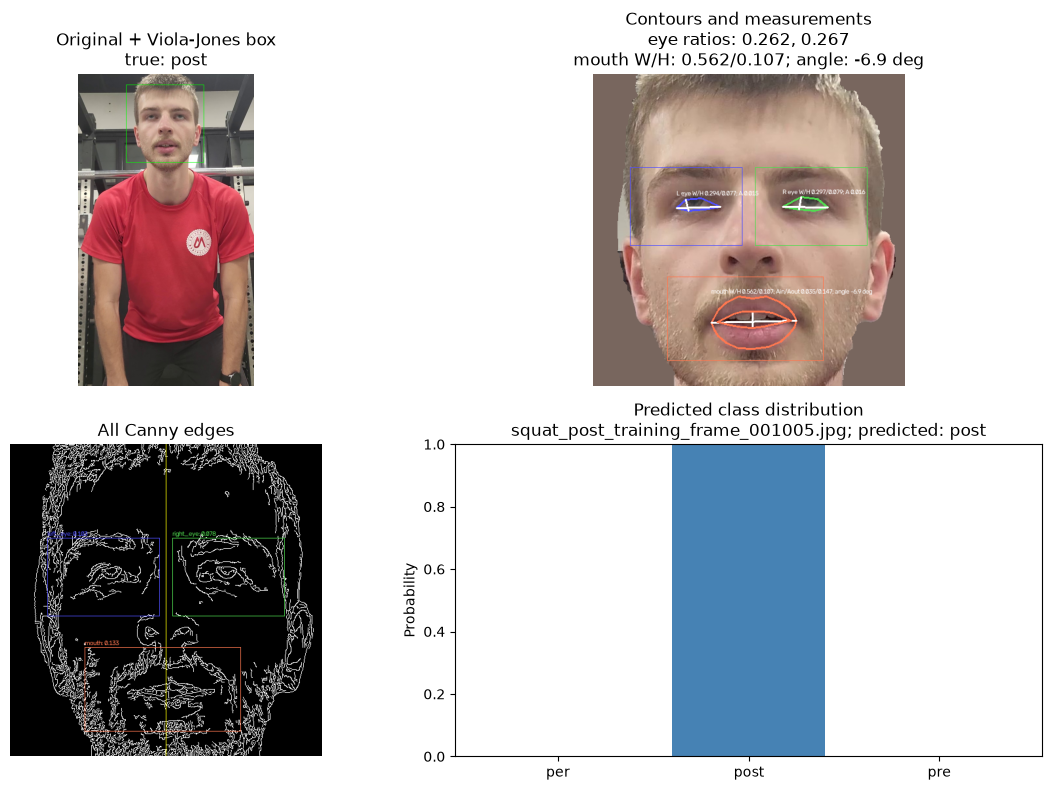

In [ ]:
# Visual sanity check: one random test image
sample = test.sample(n=1, random_state=SEED).iloc[0]
image = cv2.imread(sample["path"])
face, bbox = face_detect(sample["path"])
if face is None or bbox is None:
    raise RuntimeError(f"No face detected in visualization sample: {sample['path']}")
face, _ = remove_face_background(face)

sample_features = data.loc[data["path"] == sample["path"], FEATURES]
probabilities = final_model.predict_proba(sample_features)[0]
geometry = extract_contour_features(face)
face_height, face_width = face.shape[:2]

def _face_roi(x0, y0, x1, y1):
    return face[int(face_height * y0):int(face_height * y1),
                int(face_width * x0):int(face_width * x1)]

gray_face = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY)
regions = {
    "left_eye": (0.12, 0.30, 0.48, 0.55),
    "right_eye": (0.52, 0.30, 0.88, 0.55),
    "mouth": (0.24, 0.65, 0.74, 0.92),
}
contour_view = face.copy()
colors = {"left_eye": (255, 80, 80), "right_eye": (80, 220, 80), "mouth": (80, 120, 255)}
for name, (x0, y0, x1, y1) in regions.items():
    x_start, y_start = int(face_width * x0), int(face_height * y0)
    roi = _face_roi(x0, y0, x1, y1)
    roi_gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    region_geometry = {"mask": np.zeros_like(roi_gray), "contour": None,
                      "ellipse": None, "detection_box": None}
    mask = region_geometry["mask"]
    contour = region_geometry["contour"]
    detection_box = region_geometry["detection_box"]
    if detection_box is not None:
        dx, dy, dw, dh = detection_box
        cv2.rectangle(contour_view, (x_start + dx, y_start + dy),
                      (x_start + dx + dw, y_start + dy + dh), colors[name], 1)
    if contour is not None:
        shifted = contour.copy()
        shifted[:, :, 0] += x_start
        shifted[:, :, 1] += y_start
        cv2.drawContours(contour_view, [shifted], -1, colors[name], 2)
    ellipse = region_geometry["ellipse"]
    if ellipse is not None:
        (centre, axes, angle) = ellipse
        centre = (int(centre[0] + x_start), int(centre[1] + y_start))
        ellipse_axes = (max(1, int(axes[0] / 2)), max(1, int(axes[1] / 2)))
        cv2.ellipse(contour_view, centre, ellipse_axes, angle, 0, 360, (255, 255, 255), 2)
        angle_rad = np.deg2rad(angle)
        major_vector = np.array([np.cos(angle_rad), np.sin(angle_rad)]) * axes[0] / 2
        minor_vector = np.array([-np.sin(angle_rad), np.cos(angle_rad)]) * axes[1] / 2
        major_start = tuple(np.rint(np.array(centre) - major_vector).astype(int))
        major_end = tuple(np.rint(np.array(centre) + major_vector).astype(int))
        minor_start = tuple(np.rint(np.array(centre) - minor_vector).astype(int))
        minor_end = tuple(np.rint(np.array(centre) + minor_vector).astype(int))
        cv2.line(contour_view, major_start, major_end, (255, 255, 255), 2)
        cv2.line(contour_view, minor_start, minor_end, (255, 255, 255), 2)
        cv2.putText(contour_view, f"W {region_geometry['width']:.2f} H {region_geometry['height']:.2f}",
                    (x_start, max(12, y_start - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.35, (255, 255, 255), 1)
    cv2.rectangle(contour_view, (x_start, y_start),
                  (int(face_width * x1), int(face_height * y1)), colors[name], 1)

diagnostic_points = _landmark_points(face)
if diagnostic_points is not None:
    diagnostic_groups = {name: _landmark_polygon(diagnostic_points, indices)
                         for name, indices in _LANDMARK_GROUPS.items()}
    for name, points in diagnostic_groups.items():
        color_name = "mouth" if name.startswith("mouth") else name
        color = colors.get(color_name, (255, 255, 255))
        polygon = np.rint(points).astype(np.int32).reshape(-1, 1, 2)
        cv2.polylines(contour_view, [polygon], True, color, 2)
        if name == "left_eye":
            cv2.line(contour_view, tuple(np.rint(diagnostic_points[33]).astype(int)),
                     tuple(np.rint(diagnostic_points[133]).astype(int)), (255, 255, 255), 2)
            cv2.line(contour_view, tuple(np.rint(diagnostic_points[160]).astype(int)),
                     tuple(np.rint(diagnostic_points[144]).astype(int)), (255, 255, 255), 2)
            label = (f"L eye W/H {geometry['eye_left_width']:.3f}/{geometry['eye_left_height']:.3f}; "
                     f"A {geometry['eye_left_area']:.3f}")
        elif name == "right_eye":
            cv2.line(contour_view, tuple(np.rint(diagnostic_points[362]).astype(int)),
                     tuple(np.rint(diagnostic_points[263]).astype(int)), (255, 255, 255), 2)
            cv2.line(contour_view, tuple(np.rint(diagnostic_points[385]).astype(int)),
                     tuple(np.rint(diagnostic_points[380]).astype(int)), (255, 255, 255), 2)
            label = (f"R eye W/H {geometry['eye_right_width']:.3f}/{geometry['eye_right_height']:.3f}; "
                     f"A {geometry['eye_right_area']:.3f}")
        elif name == "mouth_outer":
            cv2.line(contour_view, tuple(np.rint(diagnostic_points[61]).astype(int)),
                     tuple(np.rint(diagnostic_points[291]).astype(int)), (255, 255, 255), 2)
            cv2.line(contour_view, tuple(np.rint(diagnostic_points[13]).astype(int)),
                     tuple(np.rint(diagnostic_points[14]).astype(int)), (255, 255, 255), 2)
            label = (f"mouth W/H {geometry['mouth_width']:.3f}/{geometry['mouth_height']:.3f}; "
                     f"Ain/Aout {geometry['mouth_inner_area']:.3f}/{geometry['mouth_outer_area']:.3f}; "
                     f"angle {geometry['mouth_corner_angle_deg']:.1f} deg")
        else:
            label = None
        if label:
            text_origin = tuple(np.rint(points.min(axis=0)).astype(int))
            cv2.putText(contour_view, label, (max(0, text_origin[0]), max(12, text_origin[1] - 4)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.35, (255, 255, 255), 1)

edge_view = cv2.cvtColor(cv2.Canny(gray_face, 30, 100), cv2.COLOR_GRAY2BGR)
cv2.line(edge_view, (face_width // 2, 0), (face_width // 2, face_height), (0, 255, 255), 1)
for name, (x0, y0, x1, y1) in regions.items():
    x_start, y_start = int(face_width * x0), int(face_height * y0)
    x_end, y_end = int(face_width * x1), int(face_height * y1)
    roi_edges = cv2.Canny(gray_face[y_start:y_end, x_start:x_end], 30, 100)
    density = np.mean(roi_edges > 0)
    cv2.rectangle(edge_view, (x_start, y_start), (x_end, y_end), colors[name], 1)
    cv2.putText(edge_view, f"{name}: {density:.3f}", (x_start, max(12, y_start - 3)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.35, colors[name], 1)
original_view = image.copy()
x, y, w, h = bbox
cv2.rectangle(original_view, (x, y), (x + w, y + h), (0, 255, 0), 2)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].imshow(cv2.cvtColor(original_view, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title(f"Original + Viola-Jones box\ntrue: {sample['condition']}")
axes[0, 1].imshow(cv2.cvtColor(contour_view, cv2.COLOR_BGR2RGB))
axes[0, 1].set_title(f"Contours and measurements\n"
                      f"eye ratios: {geometry['eye_left_opening_ratio']:.3f}, {geometry['eye_right_opening_ratio']:.3f}\n"
                      f"mouth W/H: {geometry['mouth_width']:.3f}/{geometry['mouth_height']:.3f}; angle: {geometry['mouth_corner_angle_deg']:.1f} deg")
axes[1, 0].imshow(cv2.cvtColor(edge_view, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title("All Canny edges")
axes[1, 1].bar(final_model.classes_, probabilities, color="steelblue")
axes[1, 1].set_ylim(0, 1)
axes[1, 1].set_ylabel("Probability")
axes[1, 1].set_title(f"Predicted class distribution\n"
                     f"{Path(sample['path']).name}; predicted: {final_model.predict(sample_features)[0]}")
for axis in (axes[0, 0], axes[0, 1], axes[1, 0]):
    axis.axis("off")
plt.tight_layout()
plt.show()


Now, let us determine what features among the most important ones should we follow temporally.

In [21]:
# RF classification on test set with the top 1 feature trained on train + val
top_features_1 = imp.sort_values(ascending=False).head(1).index.tolist()
X_test_top_1 = X_test[top_features_1]
rf.fit(pd.concat([X_train[top_features_1], X_val[top_features_1]]), pd.concat([y_train, y_val]))
y_pred_1 = rf.predict(X_test_top_1)

print(f"Random Forest with top 1 feature: {top_features_1}")
print(f"Accuracy          : {accuracy_score(y_test, y_pred_1):.3f}")

# RF classification on test set with the top 2 features trained on train + val
top_features_2 = imp.sort_values(ascending=False).head(2).index.tolist()
X_test_top_2 = X_test[top_features_2]
rf.fit(pd.concat([X_train[top_features_2], X_val[top_features_2]]), pd.concat([y_train, y_val]))
y_pred_2 = rf.predict(X_test_top_2)

print(f"Random Forest with top 2 features: {top_features_2}")
print(f"Accuracy          : {accuracy_score(y_test, y_pred_2):.3f}")

# RF classification on test set with the top 3 features trained on train + val
top_features_3 = imp.sort_values(ascending=False).head(3).index.tolist()
X_test_top_3 = X_test[top_features_3]
rf.fit(pd.concat([X_train[top_features_3], X_val[top_features_3]]), pd.concat([y_train, y_val]))
y_pred_3 = rf.predict(X_test_top_3)

print(f"Random Forest with top 3 features: {top_features_3}")
print(f"Accuracy          : {accuracy_score(y_test, y_pred_3):.3f}")

# Random Forest classification on test set with the top 5 features trained on train + val
top_features = imp.sort_values(ascending=False).head(5).index.tolist()
X_test_top = X_test[top_features]
rf.fit(pd.concat([X_train[top_features], X_val[top_features]]), pd.concat([y_train, y_val]))
y_pred = rf.predict(X_test_top)

print(f"Random Forest with top 5 features: {top_features}")
print(f"Accuracy          : {accuracy_score(y_test, y_pred):.3f}")

# Same with 10 features
top_features_10 = imp.sort_values(ascending=False).head(10).index.tolist()
X_test_top_10 = X_test[top_features_10]
rf.fit(pd.concat([X_train[top_features_10], X_val[top_features_10]]), pd.concat([y_train, y_val]))
y_pred_10 = rf.predict(X_test_top_10)

print(f"Random Forest with top 10 features: {top_features_10}")
print(f"Accuracy          : {accuracy_score(y_test, y_pred_10):.3f}")

# KNN classification on test set with the top 10 features
knn.fit(pd.concat([X_train[top_features_10], X_val[top_features_10]]), pd.concat([y_train, y_val]))
y_pred_knn_10 = knn.predict(X_test_top_10)

print(f"KNN with top 10 features: {top_features_10}")
print(f"Accuracy          : {accuracy_score(y_test, y_pred_knn_10):.3f}")

Random Forest with top 1 feature: ['mouth_opening_ratio']
Accuracy          : 0.483
Random Forest with top 2 features: ['mouth_opening_ratio', 'mouth_corner_angle_deg']
Accuracy          : 0.710
Random Forest with top 3 features: ['mouth_opening_ratio', 'mouth_corner_angle_deg', 'mouth_edge_density']
Accuracy          : 0.863
Random Forest with top 5 features: ['mouth_opening_ratio', 'mouth_corner_angle_deg', 'mouth_edge_density', 'eye_left_edge_density', 'mouth_width']
Accuracy          : 0.887
Random Forest with top 10 features: ['mouth_opening_ratio', 'mouth_corner_angle_deg', 'mouth_edge_density', 'eye_left_edge_density', 'mouth_width', 'mouth_inner_area', 'mouth_height', 'eye_right_width', 'eye_edge_density_asymmetry', 'eye_right_opening_ratio']
Accuracy          : 0.917
KNN with top 10 features: ['mouth_opening_ratio', 'mouth_corner_angle_deg', 'mouth_edge_density', 'eye_left_edge_density', 'mouth_width', 'mouth_inner_area', 'mouth_height', 'eye_right_width', 'eye_edge_density_as

**Conclusion**: In terms of morphology, we should follow the following top 3 features:
- mouth_opening_ratio
- mouth_corner_angle_deg
- mouth_edge_density

Let us compute general statistics of these features according to each three conditions before entering the temporal world.